# Step 3 · Edge friction and baseline comparison

**Run this notebook next.** It reuses the cleaned data and full-area GeoAI predictions. It does not rerun imagery inference or train an unsupported friction model.

## 1. What is ready?
- Four ZIP areas: 75023, 75024, 75025, 75074.
- Clean block boundaries, directed walking edges, predicted trees, traffic context and Landsat surface temperature.
- The network is a prototype: entrances, crossings and disconnected routes still need review.
- Imperviousness and verified intersection attributes are **not yet included**. Keep them out of the claimed model inputs.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "scripts/build_step3_friction.py").exists(), "Open this notebook inside the EmPath project."
sys.path.insert(0, str(ROOT / "scripts"))
from build_step3_friction import run


## 2. Choose honest learning targets

**Already learned:** a pretrained tree-segmentation model predicts trees from aerial imagery. The resulting tree fraction is measured around each edge in a 5 m corridor; it is not actual shade.

**Available behavioral evidence:** a small public Singapore route-choice dataset supports a fitted distance/sun trade-off. It does not provide Plano labels for traffic, heat or crossing difficulty. Existing evaluation is saved in `output/route_preference_model/`.

**Decision for this prototype:** use the existing transferred canopy model as one comparison and explicitly assumed equal-weight environmental scenarios as the other. Do not train XGBoost to reproduce the hand-built index and call that validation.

Reference: Melnikov et al. (2022), *Behavioural thermal regulation explains pedestrian path choices in hot urban environments*. https://doi.org/10.1038/s41598-022-06383-5 · Public data: https://osf.io/aj4vk/


In [2]:
model = json.loads((ROOT / "output/route_preference_model/model_and_evaluation.json").read_text())
cv = model["grouped_cross_validation"]
display(pd.DataFrame({name: cv[name] for name in ["distance_only", "distance_and_sun"]}).T)
print("These are held-out participant results from Singapore, not Plano accuracy.")


,log_loss,brier_score,accuracy,observations
distance_only,0.581065,0.194079,0.732843,408.0
distance_and_sun,0.577136,0.193747,0.727941,408.0


These are held-out participant results from Singapore, not Plano accuracy.


## 3. Calculate a cost for each walking edge

Think of each edge as one short piece of a walk. Ordinary routing adds up minutes. Friction routing adds up **equivalent minutes**: exposed, high-traffic or hot pieces receive extra cost.

- **Time baseline:** `length / 1.2` seconds, assuming a constant walking speed.
- **Transferred canopy proxy:** `time × [1 + beta × (1 − predicted tree fraction)]`.
- **Three-factor scenario:** `time × [1 + lambda × mean(canopy deficit, normalized traffic, normalized surface temperature)]`.
- Try `lambda = 0.5, 1, 2` to see how sensitive routes are to the assumed penalty strength. At lambda 1, a fully burdened edge has twice its ordinary cost.

Temperature uses the existing midpoint block ID. It is a coarse contextual assignment, **not a new segment temperature measurement**. Traffic retains its City-of-Plano reference; temperature retains its four-ZIP reference.

Unknown required data stays unknown. Each scenario is compared with a time-only route on the **same supported edges**. The full-network fastest time is also reported so data exclusions are visible. Routes are illustrative and do not certify safe or legal access.


In [3]:
report, comparison = run()
display(pd.DataFrame.from_dict(report["cost_feature_coverage"], orient="index", columns=["edges_with_cost"]))
display(pd.Series(report["checks"], name="Passed"))


,edges_with_cost
time_only_s,93452
transferred_canopy_cost_s,89486
scenario_lambda_0_5_cost_s,80110
scenario_lambda_1_0_cost_s,80110
scenario_lambda_2_0_cost_s,80110


unique_edge_ids                         True
positive_known_baseline_times           True
costs_at_least_baseline                 True
missing_factor_stays_unknown            True
homogeneous_subdivision_invariance      True
weighted_routes_minimize_stated_cost    True
Name: Passed, dtype: bool

## 4. Compare routes

For each ZIP, compare the ordinary route and friction route between the same two existing illustrative endpoints. Look for extra actual minutes, changes in tree adjacency, traffic and heat, and lower **scenario cost**. A lower scenario cost is successful optimization of the chosen formula, not evidence that people prefer the route.

Some routes may stay the same. Report that honestly; do not tune weights merely to force a visually different result.


In [4]:
columns = ["zip", "scenario", "route", "network_walk_minutes", "distance_m", "scenario_cost_equivalent_minutes", "mean_ai_tree_cover_01", "mean_traffic_burden_01", "mean_temperature_burden_01", "changed_from_same_support_time_route"]
display(comparison.reindex(columns=columns).round(3))


,zip,scenario,route,network_walk_minutes,distance_m,scenario_cost_equivalent_minutes,mean_ai_tree_cover_01,mean_traffic_burden_01,mean_temperature_burden_01,changed_from_same_support_time_route
0,75023,transferred_canopy_cost_s,time_only_same_support,11.665,839.869,13.747,0.063,0.761,NaN,False
1,75023,transferred_canopy_cost_s,friction_route,11.665,839.869,13.747,0.063,0.761,NaN,False
2,75024,transferred_canopy_cost_s,time_only_same_support,13.736,989.023,16.349,0.002,NaN,0.687,False
3,75024,transferred_canopy_cost_s,friction_route,13.736,989.023,16.349,0.002,NaN,0.687,False
4,75025,transferred_canopy_cost_s,time_only_same_support,13.388,963.954,15.688,0.099,0.653,0.699,True
5,75025,transferred_canopy_cost_s,friction_route,13.407,965.295,15.644,0.124,0.645,0.697,True
6,75074,transferred_canopy_cost_s,time_only_same_support,9.525,685.807,11.159,0.100,NaN,0.664,True
7,75074,transferred_canopy_cost_s,friction_route,9.535,686.496,11.108,0.134,NaN,0.663,True
8,75023,scenario_lambda_0_5_cost_s,time_only_same_support,11.786,848.556,16.466,0.064,0.763,0.684,False
9,75023,scenario_lambda_0_5_cost_s,friction_route,11.786,848.556,16.466,0.064,0.763,0.684,False


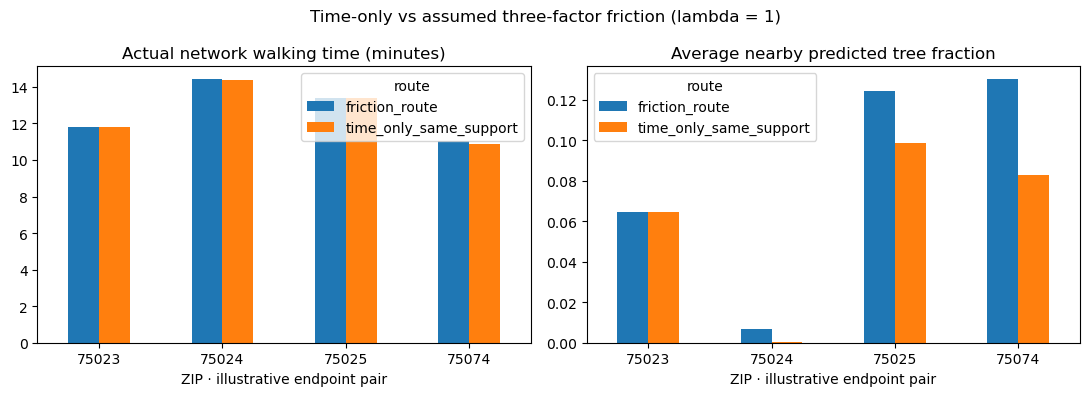

In [5]:
import matplotlib.pyplot as plt
subset = comparison[(comparison.scenario == "scenario_lambda_1_0_cost_s") & comparison.route.notna()]
if not subset.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, field, title in [(axes[0], "network_walk_minutes", "Actual network walking time (minutes)"), (axes[1], "mean_ai_tree_cover_01", "Average nearby predicted tree fraction")]:
        subset.pivot(index="zip", columns="route", values=field).plot.bar(ax=ax, rot=0)
        ax.set_title(title)
        ax.set_xlabel("ZIP · illustrative endpoint pair")
    fig.suptitle("Time-only vs assumed three-factor friction (lambda = 1)")
    fig.tight_layout()
    fig.savefig(ROOT / "output/step3_friction/benchmark_summary.png", dpi=170, bbox_inches="tight")
    plt.show()


## 5. Handoff checklist

- [ ] Review `output/step3_friction/method_and_readiness.json` and missing-feature counts.
- [ ] Inspect `route_benchmark.csv`; choose a clear, honestly labeled demonstration.
- [ ] Open `benchmark_routes.gpkg` in Python if you need a map of those exact routes.
- [ ] Verify the demonstration's real entrances, crossings, sidewalks and access restrictions.
- [ ] Keep imperviousness/crossing features optional unless usable inputs are actually joined.
- [ ] Present formula weights as assumptions; report Singapore transfer and local validation limits.

**Outputs:** `edge_costs.csv`, `route_benchmark.csv`, `benchmark_routes.gpkg`, `method_and_readiness.json`, and `benchmark_summary.png`.

Do not publish individual medical or safety claims. Network-only times exclude access connectors and crossing waits. Existing website maps are not changed by this notebook.
